# Sustainability Experiment Analysis v2
## Resource Usage + Nextflow Trace Plots

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import re

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3
})

BASE_DIR = Path('~/Desktop/paper_experiments').expanduser()

EXPERIMENTS = {
    'Baseline U2': BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_06_56_27_df3720c9',
    'Baseline U4': BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_08_23_15_380543a9',
    'Reuse U2 10%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_10_34_11_31e60571',
    'Reuse U2 20%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_12_07_32_3d7b68ca',
    'Reuse U2 50%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_13_53_11_2e5a48b1',
    'Reuse U4 10%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_15_19_12_fb52d4d4',
    'Reuse U4 20%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_18_29_51_f387afe0',
    'Reuse U4 50%': BASE_DIR / 'reuse_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_27_22_10_43_9bb8ec96',
}

TRACE_DIR = BASE_DIR / 'reuse_sequential' / 'traces'
BASELINE_TRACE_DIR = BASE_DIR / 'baseline_sequential' / 'traces'

def load_csv(folder, name):
    path = Path(folder) / 'data' / name
    return pd.read_csv(path) if path.exists() else None

def load_run_json(folder):
    p = Path(folder) / 'run.json'
    return json.loads(p.read_text()) if p.exists() else None

def get_treatment(df):
    if 'treatment' in df.columns:
        return df[df['treatment'] == 'Treatment'].copy()
    return df.copy()

def get_energy(folder):
    df = load_csv(folder, 'kepler_node_cpu_power_sum.csv')
    if df is not None:
        return get_treatment(df)['kepler_node_cpu_power_sum'].sum() * 10
    return None

def get_duration(folder):
    rj = load_run_json(folder)
    return rj.get('treatment_duration') if rj else None

tasks_per_user = 548
colors_u2 = ['#1f77b4', '#aec7e8', '#6baed6', '#2171b5']
colors_u4 = ['#d62728', '#fc9272', '#ef6548', '#a50f15']
scenarios = ['Baseline', '10% Reuse', '20% Reuse', '50% Reuse']
exp_keys_u2 = ['Baseline U2', 'Reuse U2 10%', 'Reuse U2 20%', 'Reuse U2 50%']
exp_keys_u4 = ['Baseline U4', 'Reuse U4 10%', 'Reuse U4 20%', 'Reuse U4 50%']
x = np.arange(len(scenarios))
width = 0.35

print('Setup done')

Setup done


## Plot 1 — CPU Utilization Comparison (avg watts during treatment)

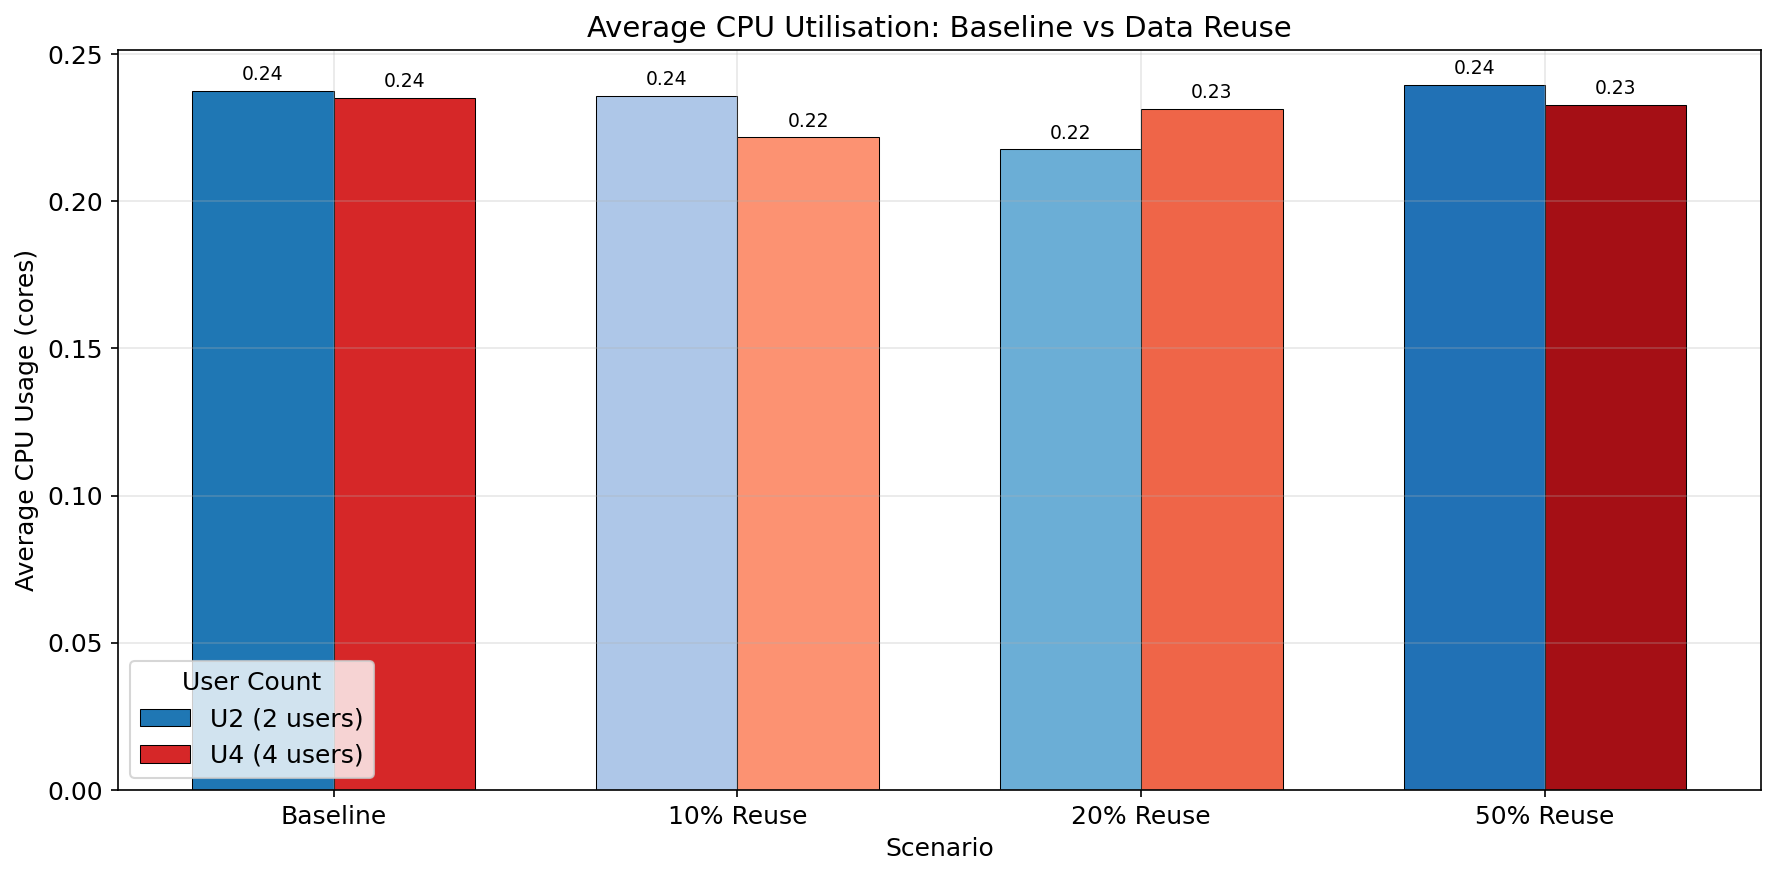

Saved: cpu_utilisation.pdf


In [2]:
fig, ax = plt.subplots(figsize=(12, 6))

def get_avg_cpu(folder):
    df = load_csv(folder, 'system_cpu_usage.csv')
    if df is not None:
        return get_treatment(df)['system_cpu_usage'].mean()
    return None

cpu_u2 = [get_avg_cpu(EXPERIMENTS[k]) or 0 for k in exp_keys_u2]
cpu_u4 = [get_avg_cpu(EXPERIMENTS[k]) or 0 for k in exp_keys_u4]

bars1 = ax.bar(x - width/2, cpu_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, cpu_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in bars1 :
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h*1.01, f'{h:.2f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h*1.01, f'{h:.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Scenario')
ax.set_ylabel('Average CPU Usage (cores)')
ax.set_title('Average CPU Utilisation: Baseline vs Data Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('cpu_utilisation.pdf', bbox_inches='tight')
plt.show()
print('Saved: cpu_utilisation.pdf')

## Plot 2 — Memory Usage Comparison (avg peak during treatment)

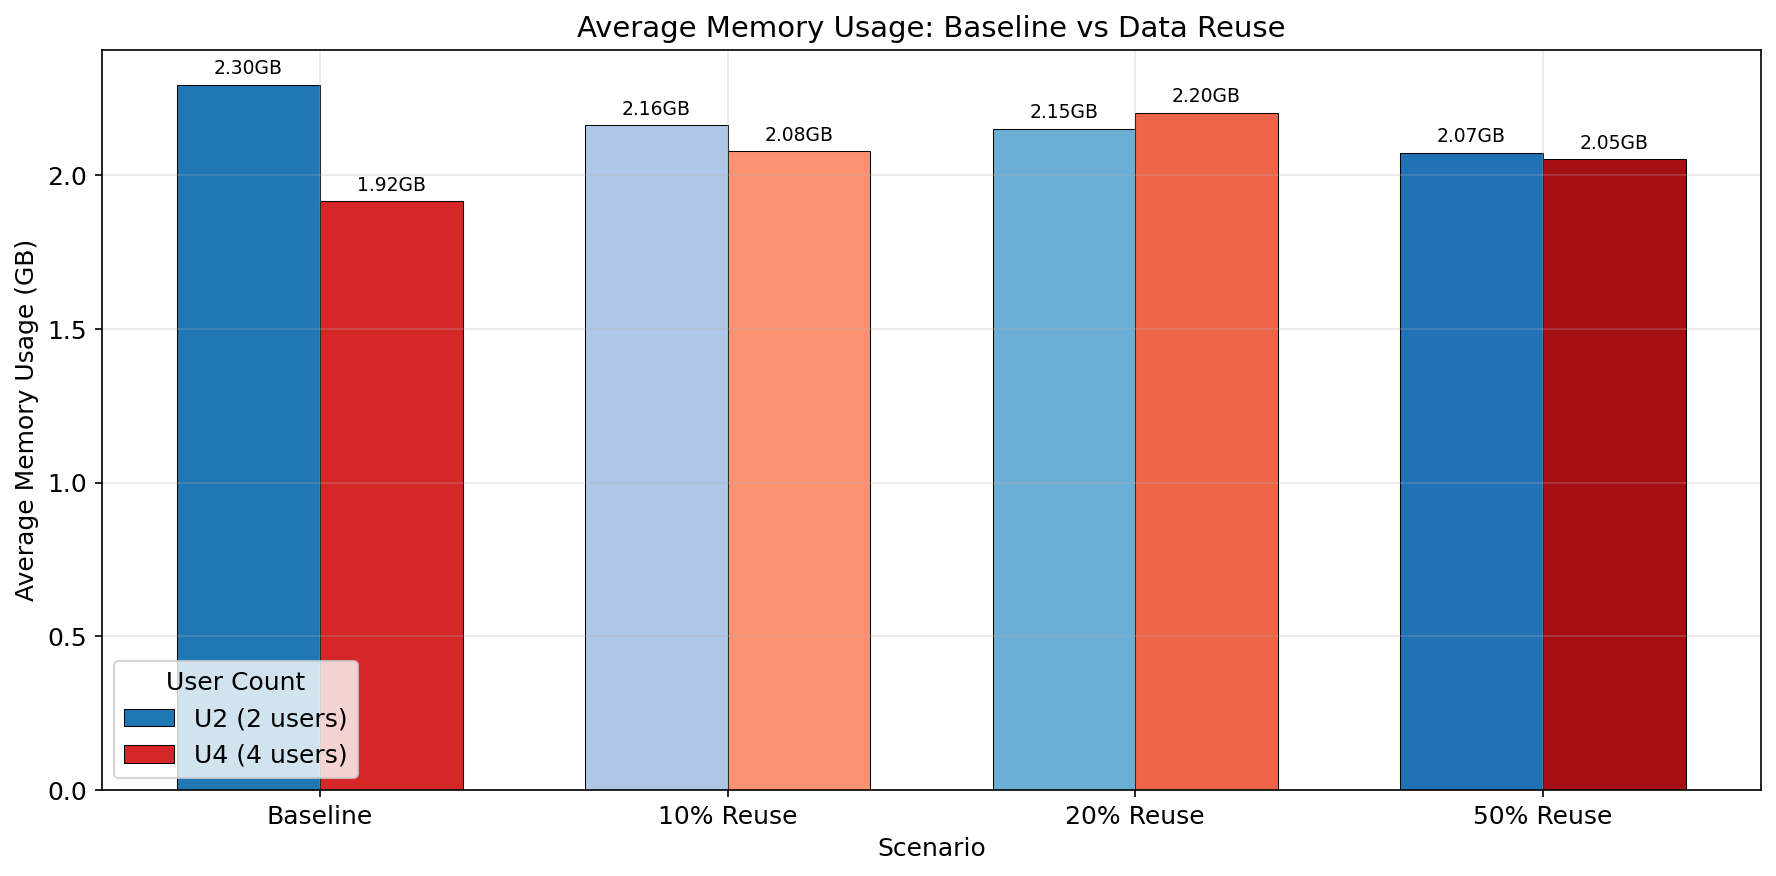

Saved: memory_usage.pdf


In [3]:
fig, ax = plt.subplots(figsize=(12, 6))

def get_avg_memory_gb(folder):
    df = load_csv(folder, 'pod_memory_usage.csv')
    if df is not None:
        return get_treatment(df)['pod_memory_usage'].mean() / (1024**3)  # bytes to GB
    return None

mem_u2 = [get_avg_memory_gb(EXPERIMENTS[k]) or 0 for k in exp_keys_u2]
mem_u4 = [get_avg_memory_gb(EXPERIMENTS[k]) or 0 for k in exp_keys_u4]

bars1 = ax.bar(x - width/2, mem_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, mem_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in bars1:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h*1.01, f'{h:.2f}GB', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2., h*1.01, f'{h:.2f}GB', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Scenario')
ax.set_ylabel('Average Memory Usage (GB)')
ax.set_title('Average Memory Usage: Baseline vs Data Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('memory_usage.pdf', bbox_inches='tight')
plt.show()
print('Saved: memory_usage.pdf')

## Plot 3 — Network I/O Comparison

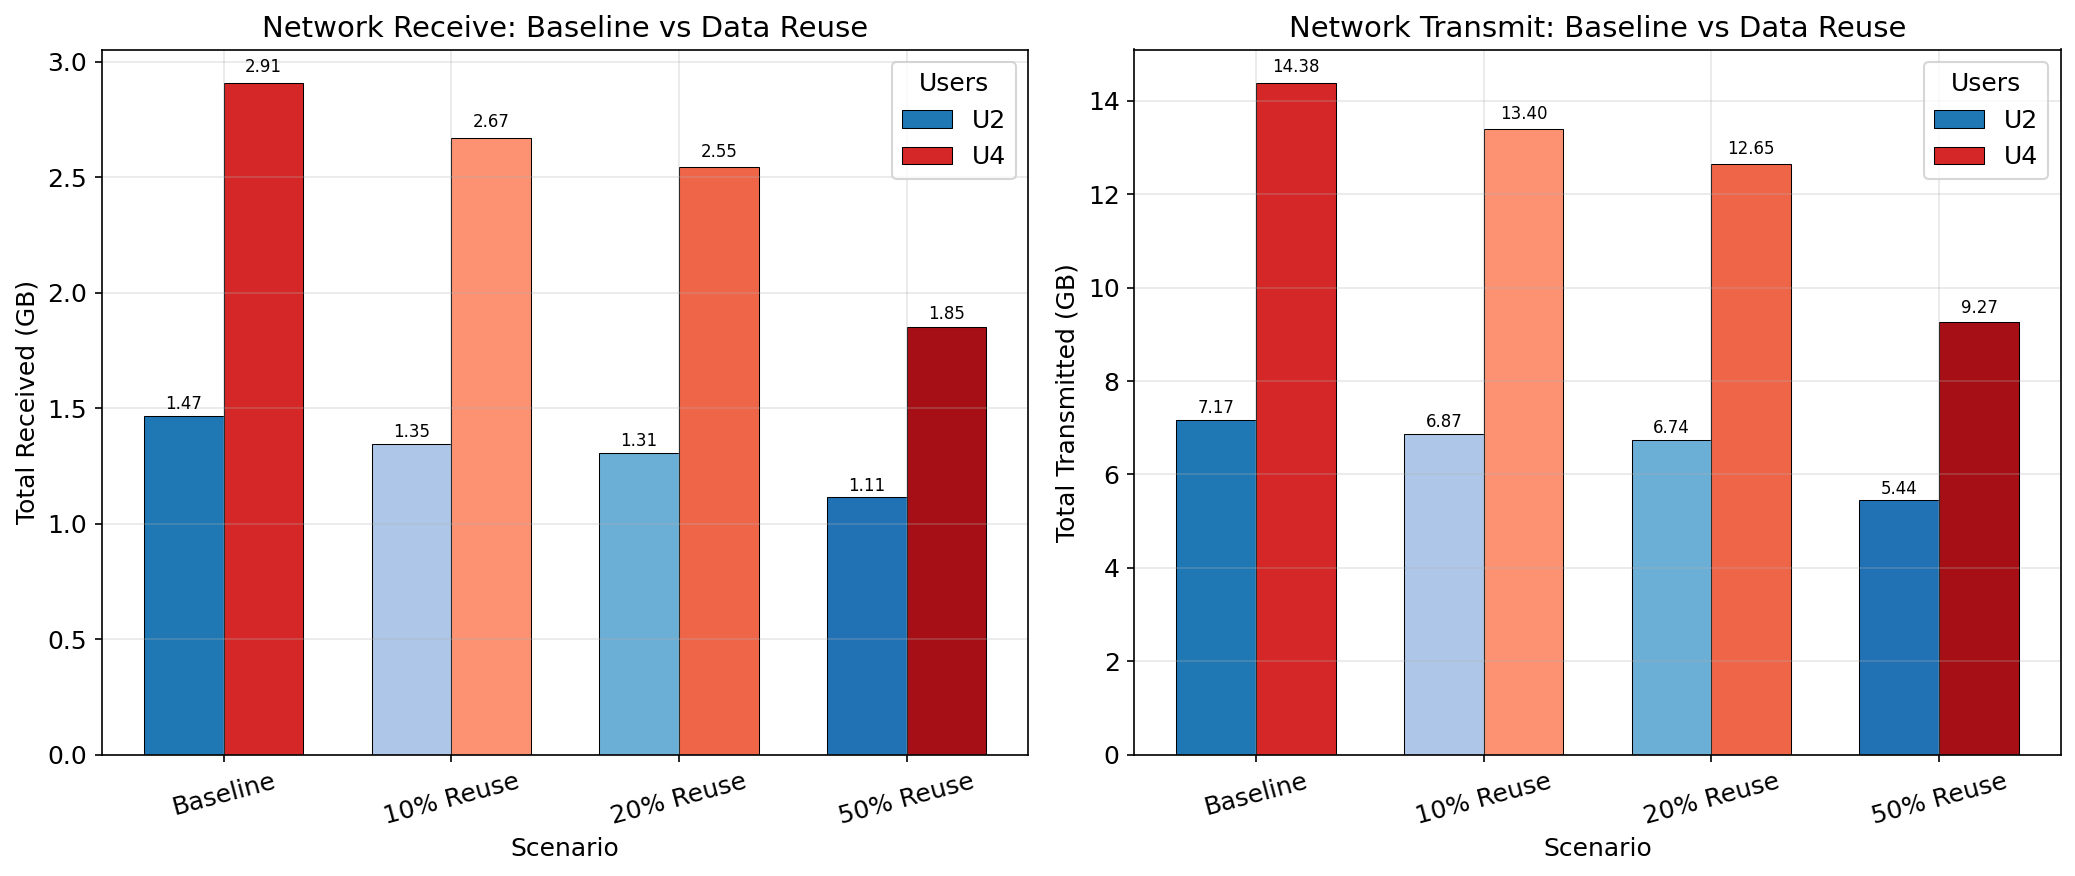

Saved: network_io.pdf


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

def get_total_network_gb(folder, csv_name, col_name):
    df = load_csv(folder, csv_name)
    if df is not None:
        return get_treatment(df)[col_name].sum() * 10 / (1024**3)  # rate * step / bytes_to_GB
    return None

rx_u2 = [get_total_network_gb(EXPERIMENTS[k], 'node_network_receive_bytes.csv', 'node_network_receive_bytes') or 0 for k in exp_keys_u2]
rx_u4 = [get_total_network_gb(EXPERIMENTS[k], 'node_network_receive_bytes.csv', 'node_network_receive_bytes') or 0 for k in exp_keys_u4]
tx_u2 = [get_total_network_gb(EXPERIMENTS[k], 'node_network_transmit_bytes.csv', 'node_network_transmit_bytes') or 0 for k in exp_keys_u2]
tx_u4 = [get_total_network_gb(EXPERIMENTS[k], 'node_network_transmit_bytes.csv', 'node_network_transmit_bytes') or 0 for k in exp_keys_u4]

for ax, data_u2, data_u4, title, ylabel in zip(
    axes,
    [rx_u2, tx_u2], [rx_u4, tx_u4],
    ['Network Receive', 'Network Transmit'],
    ['Total Received (GB)', 'Total Transmitted (GB)']
):
    bars1 = ax.bar(x - width/2, data_u2, width, label='U2', color=colors_u2, edgecolor='black', linewidth=0.5)
    bars2 = ax.bar(x + width/2, data_u4, width, label='U4', color=colors_u4, edgecolor='black', linewidth=0.5)
    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2., h*1.01, f'{h:.2f}', ha='center', va='bottom', fontsize=8)
    ax.set_xlabel('Scenario')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title}: Baseline vs Data Reuse')
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios, rotation=15)
    ax.legend(title='Users')

plt.tight_layout()
plt.savefig('network_io.pdf', bbox_inches='tight')
plt.show()
print('Saved: network_io.pdf')

## Plot 4 — CPU Over Time (Baseline U2 vs Reuse U2 50%)

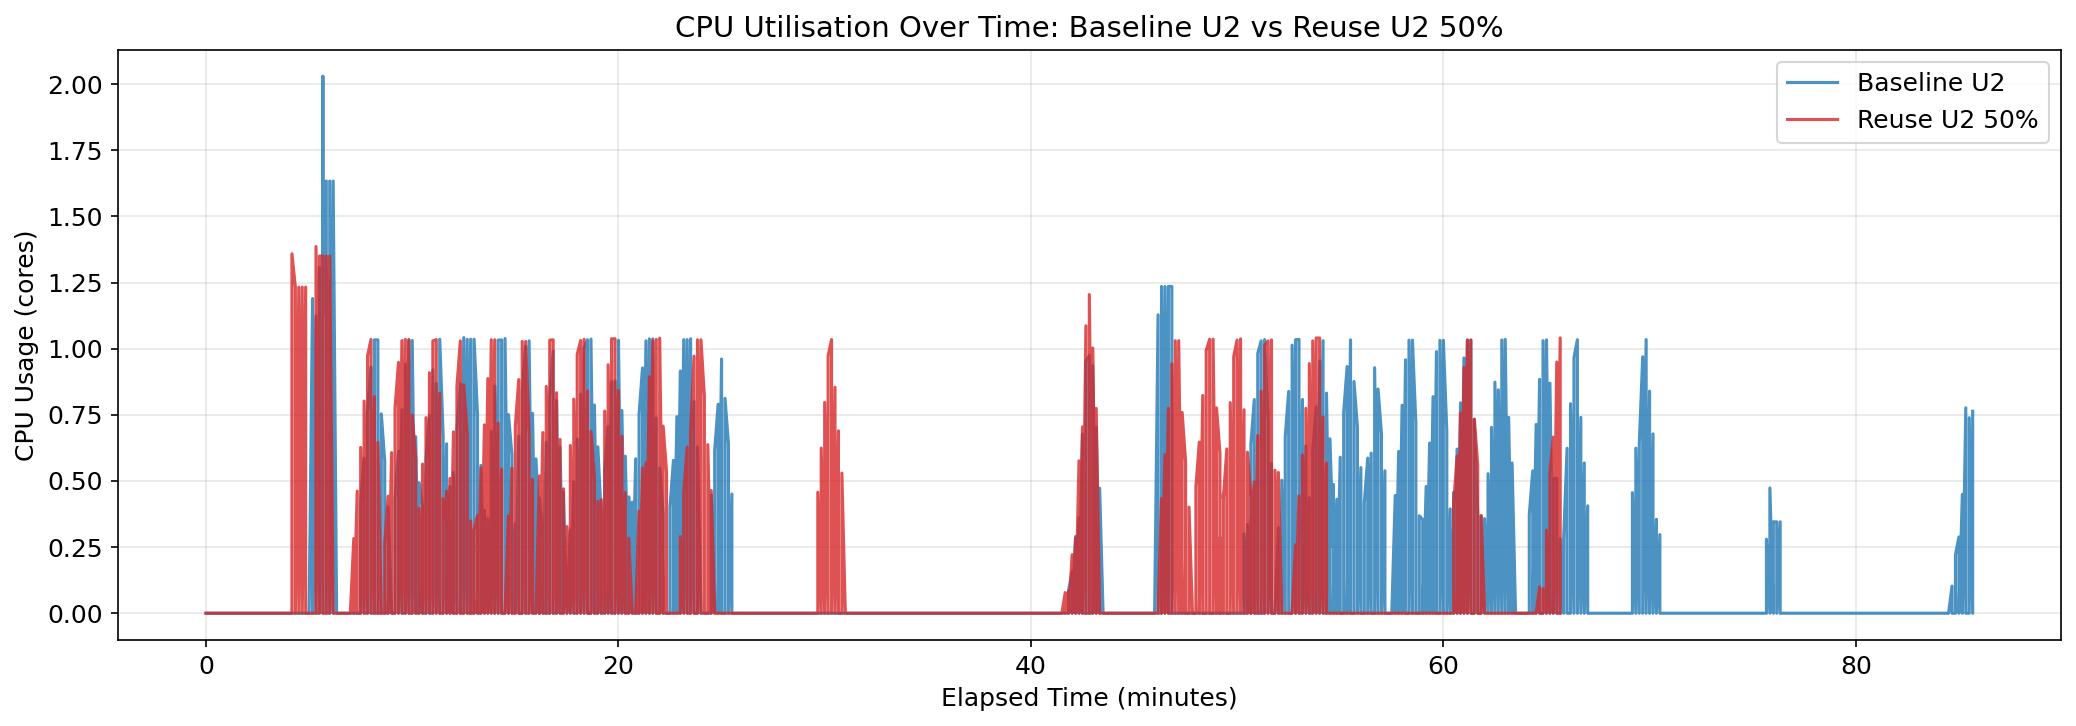

Saved: cpu_timeseries.pdf


In [5]:
fig, ax = plt.subplots(figsize=(14, 5))

def get_cpu_timeseries(folder):
    df = load_csv(folder, 'system_cpu_usage.csv')
    if df is not None:
        df = get_treatment(df).copy()
        df['timestamp.1'] = pd.to_numeric(df['timestamp.1'])
        df = df.sort_values('timestamp.1')
        df['elapsed_min'] = (df['timestamp.1'] - df['timestamp.1'].min()) / 60
        return df
    return None

df_base = get_cpu_timeseries(EXPERIMENTS['Baseline U2'])
df_reuse = get_cpu_timeseries(EXPERIMENTS['Reuse U2 50%'])

if df_base is not None:
    ax.plot(df_base['elapsed_min'], df_base['system_cpu_usage'],
            color='#1f77b4', linewidth=1.5, label='Baseline U2', alpha=0.8)
if df_reuse is not None:
    ax.plot(df_reuse['elapsed_min'], df_reuse['system_cpu_usage'],
            color='#d62728', linewidth=1.5, label='Reuse U2 50%', alpha=0.8)

ax.set_xlabel('Elapsed Time (minutes)')
ax.set_ylabel('CPU Usage (cores)')
ax.set_title('CPU Utilisation Over Time: Baseline U2 vs Reuse U2 50%')
ax.legend()
plt.tight_layout()
plt.savefig('cpu_timeseries.pdf', bbox_inches='tight')
plt.show()
print('Saved: cpu_timeseries.pdf')

## Plot 5 — Nextflow: Cached vs Computed Tasks per Scenario

In [6]:
def parse_duration(s):
    """Convert Nextflow duration string to seconds"""
    if pd.isna(s): return None
    s = str(s).strip()
    total = 0
    for val, unit in re.findall(r'([\d.]+)\s*(d|h|m|s|ms)', s):
        val = float(val)
        if unit == 'd': total += val * 86400
        elif unit == 'h': total += val * 3600
        elif unit == 'm': total += val * 60
        elif unit == 's': total += val
        elif unit == 'ms': total += val / 1000
    return total if total > 0 else None

# Load traces
TRACE_FILES = {
    'Baseline U2 - User1': BASELINE_TRACE_DIR / 'user1_baseline_20260528_065657' / 'trace.txt',
    'Baseline U2 - User2': BASELINE_TRACE_DIR / 'user2_baseline_20260528_065657' / 'trace.txt',
    'Reuse U2 10% - User2': TRACE_DIR / 'user2_reuse10pct_20260527_151942' / 'trace.txt',
    'Reuse U2 20% - User2': TRACE_DIR / 'user2_reuse20pct_20260527_183021' / 'trace.txt',
    'Reuse U2 50% - User2': TRACE_DIR / 'user2_reuse50pct_20260527_221113' / 'trace.txt',
}

trace_data = {}
for name, path in TRACE_FILES.items():
    if path.exists():
        df = pd.read_csv(path, sep='\t')
        trace_data[name] = df
        print(f"✅ {name}: {len(df)} tasks, statuses: {df['status'].value_counts().to_dict()}")
    else:
        print(f"❌ {name}: not found at {path}")

✅ Baseline U2 - User1: 548 tasks, statuses: {'COMPLETED': 548}
✅ Baseline U2 - User2: 548 tasks, statuses: {'COMPLETED': 548}
✅ Reuse U2 10% - User2: 548 tasks, statuses: {'COMPLETED': 493, 'CACHED': 55}
✅ Reuse U2 20% - User2: 548 tasks, statuses: {'COMPLETED': 449, 'CACHED': 99}
✅ Reuse U2 50% - User2: 548 tasks, statuses: {'CACHED': 274, 'COMPLETED': 274}


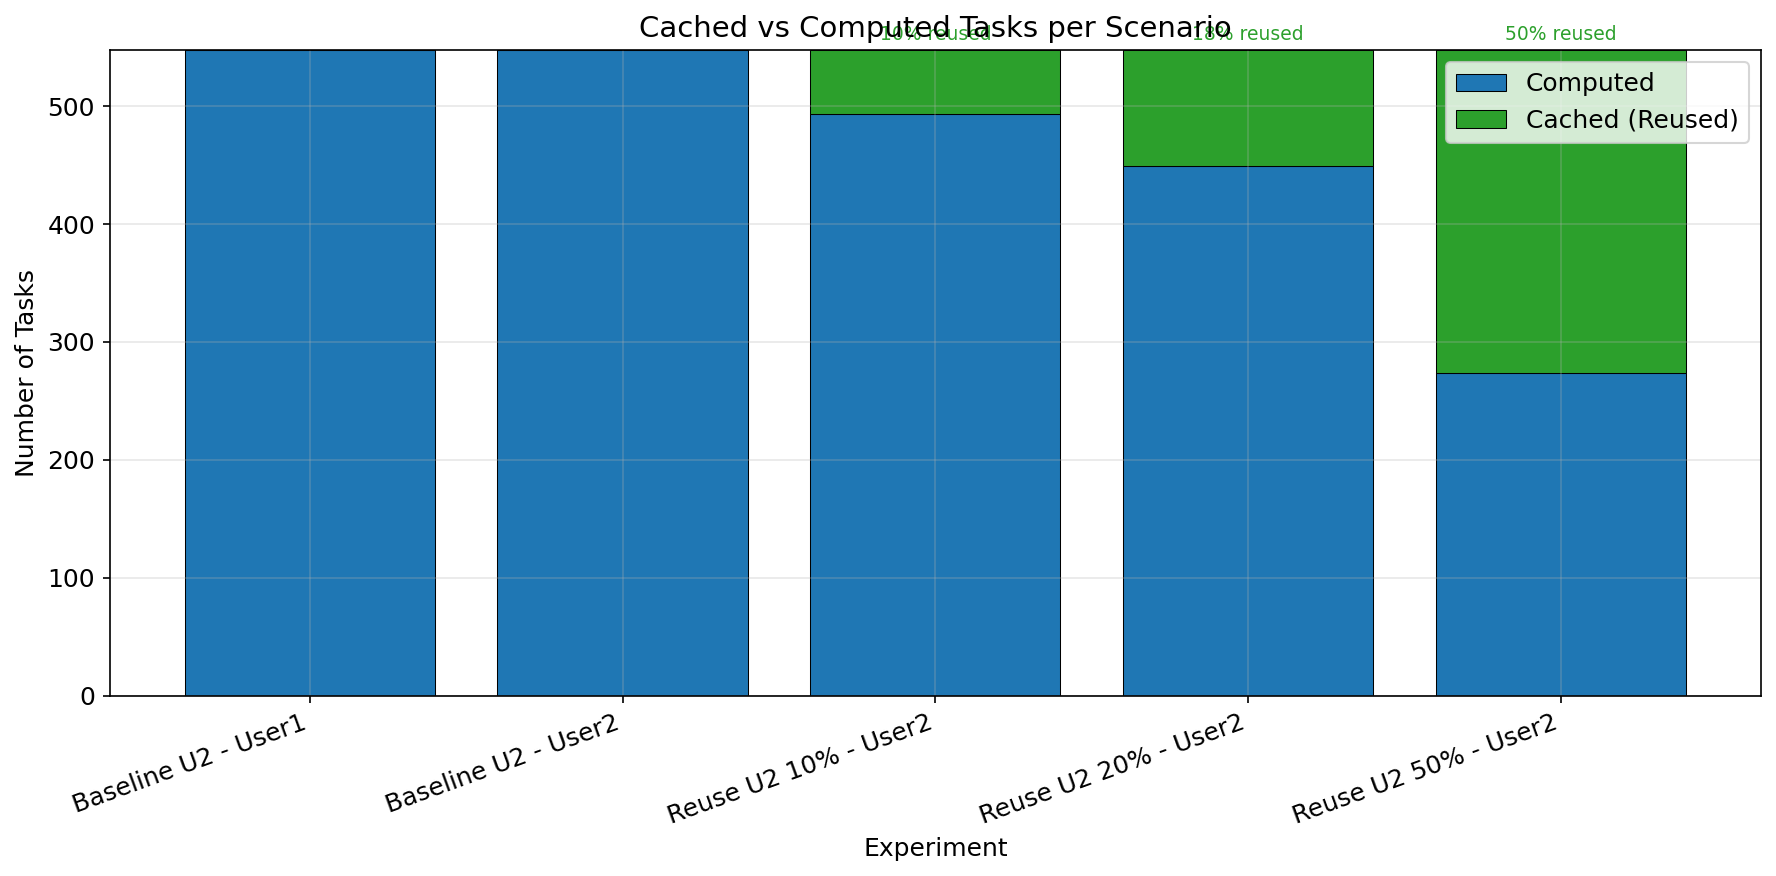

Saved: cached_vs_computed.pdf


In [7]:
# Cached vs Computed bar chart
fig, ax = plt.subplots(figsize=(12, 6))

labels = list(trace_data.keys())
cached = [len(df[df['status'] == 'CACHED']) for df in trace_data.values()]
completed = [len(df[df['status'] == 'COMPLETED']) for df in trace_data.values()]

x2 = np.arange(len(labels))
bars1 = ax.bar(x2, completed, label='Computed', color='#1f77b4', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x2, cached, bottom=completed, label='Cached (Reused)', color='#2ca02c', edgecolor='black', linewidth=0.5)

for i, (c, ca) in enumerate(zip(completed, cached)):
    total = c + ca
    if ca > 0:
        ax.text(i, total + 5, f'{ca/total*100:.0f}% reused', ha='center', va='bottom', fontsize=9, color='#2ca02c')

ax.set_xlabel('Experiment')
ax.set_ylabel('Number of Tasks')
ax.set_title('Cached vs Computed Tasks per Scenario')
ax.set_xticks(x2)
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig('cached_vs_computed.pdf', bbox_inches='tight')
plt.show()
print('Saved: cached_vs_computed.pdf')

## Plot 6 — Nextflow: Task Duration Distribution (Boxplot by Process)

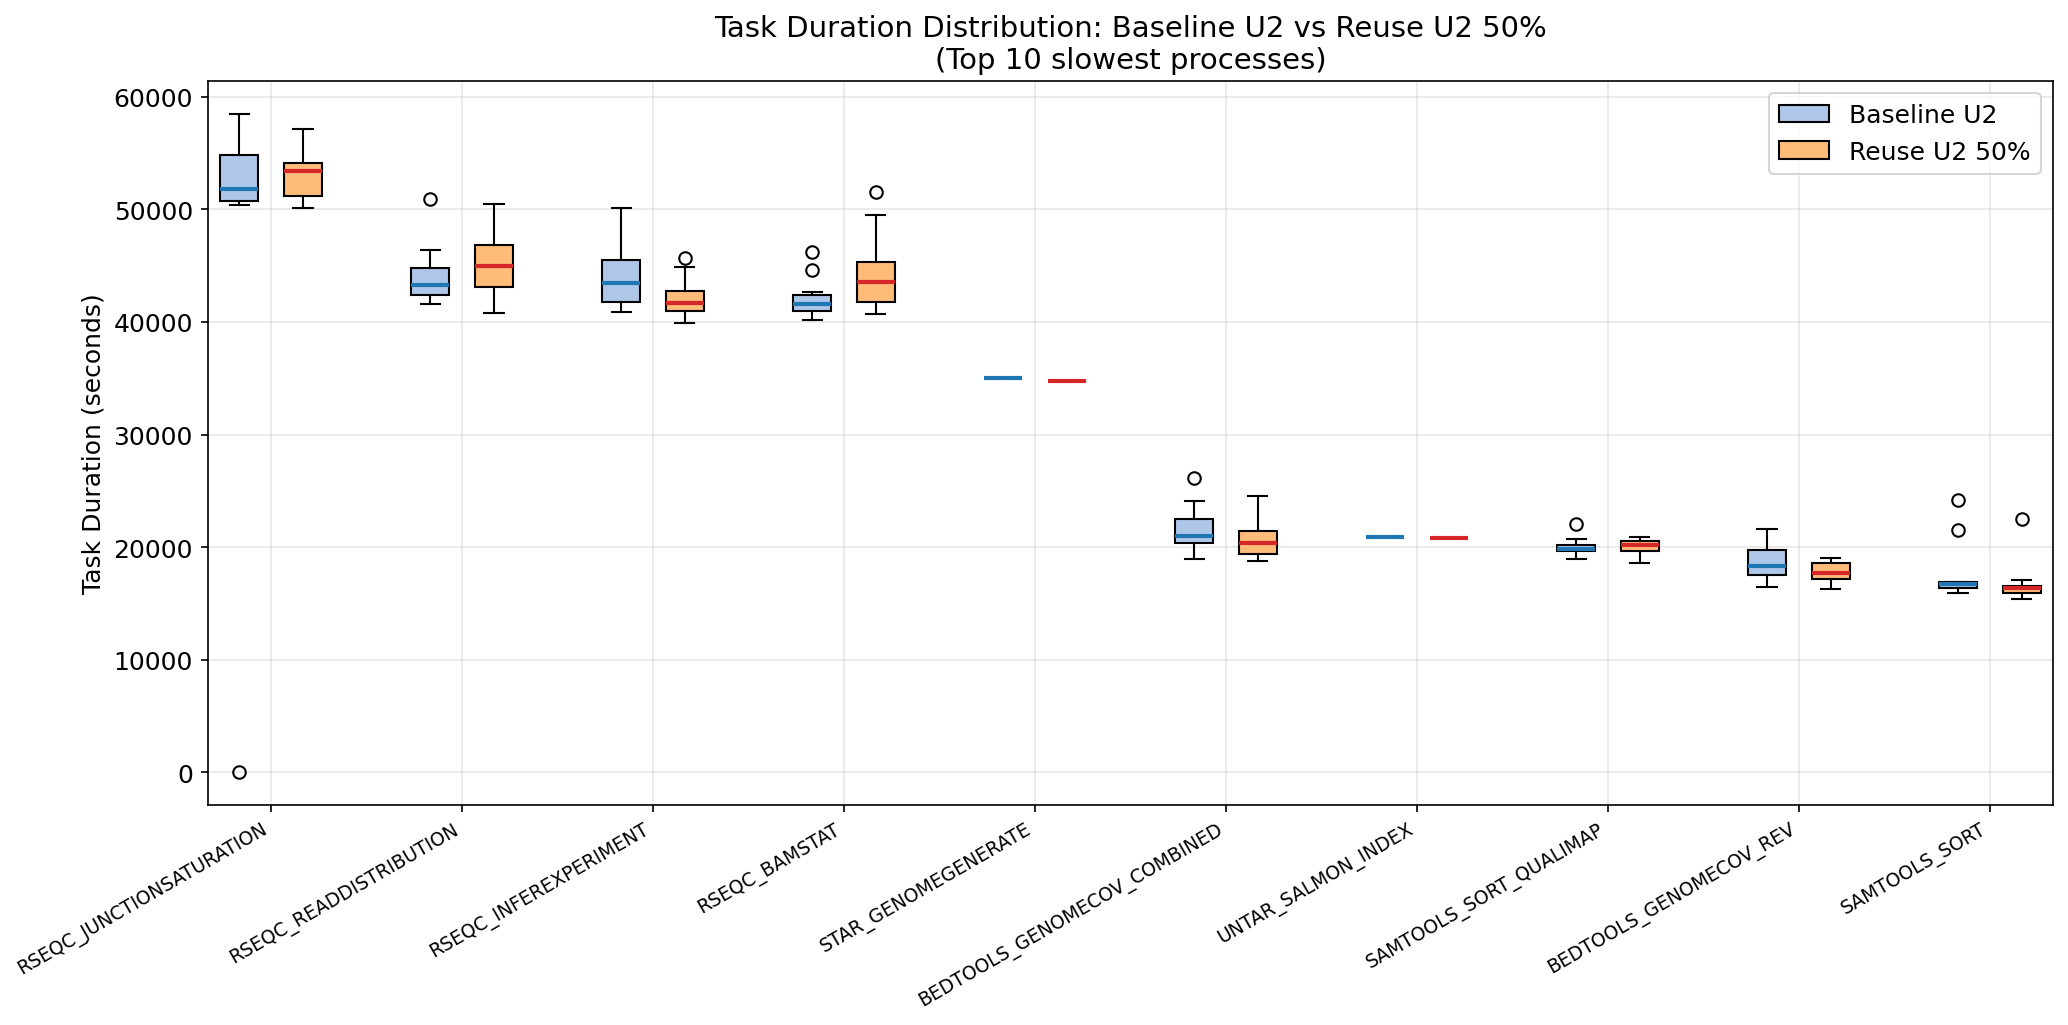

Saved: task_duration_boxplot.pdf


In [8]:
# Compare task durations between baseline and 50% reuse for top processes
def extract_process(name):
    parts = str(name).split(':')
    return parts[-1].split('(')[0].strip()

if 'Baseline U2 - User1' in trace_data and 'Reuse U2 50% - User2' in trace_data:
    df_base = trace_data['Baseline U2 - User1'].copy()
    df_reuse = trace_data['Reuse U2 50% - User2'].copy()

    df_base['duration_s'] = df_base['realtime'].apply(parse_duration)
    df_reuse['duration_s'] = df_reuse['realtime'].apply(parse_duration)
    df_base['process'] = df_base['name'].apply(extract_process)
    df_reuse['process'] = df_reuse['name'].apply(extract_process)

    # Top 10 slowest processes in baseline
    top_procs = df_base.groupby('process')['duration_s'].mean().nlargest(10).index.tolist()

    fig, ax = plt.subplots(figsize=(14, 7))
    positions_base = np.arange(len(top_procs)) * 3
    positions_reuse = positions_base + 1

    data_base = [df_base[df_base['process'] == p]['duration_s'].dropna().values for p in top_procs]
    data_reuse = [df_reuse[df_reuse['process'] == p]['duration_s'].dropna().values for p in top_procs]

    bp1 = ax.boxplot(data_base, positions=positions_base, widths=0.6,
                     patch_artist=True, boxprops=dict(facecolor='#aec7e8'),
                     medianprops=dict(color='#1f77b4', linewidth=2))
    bp2 = ax.boxplot(data_reuse, positions=positions_reuse, widths=0.6,
                     patch_artist=True, boxprops=dict(facecolor='#ffbb78'),
                     medianprops=dict(color='#d62728', linewidth=2))

    ax.set_xticks(positions_base + 0.5)
    ax.set_xticklabels(top_procs, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel('Task Duration (seconds)')
    ax.set_title('Task Duration Distribution: Baseline U2 vs Reuse U2 50%\n(Top 10 slowest processes)')
    ax.legend([bp1['boxes'][0], bp2['boxes'][0]], ['Baseline U2', 'Reuse U2 50%'])
    plt.tight_layout()
    plt.savefig('task_duration_boxplot.pdf', bbox_inches='tight')
    plt.show()
    print('Saved: task_duration_boxplot.pdf')

## Plot 7 — Nextflow: CPU Hours Saved by Reuse

/var/folders/vk/d03r7hzd5p9c3zdtvt3xrhc40000gn/T/ipykernel_12530/3987546522.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, rotation=20, ha='right')


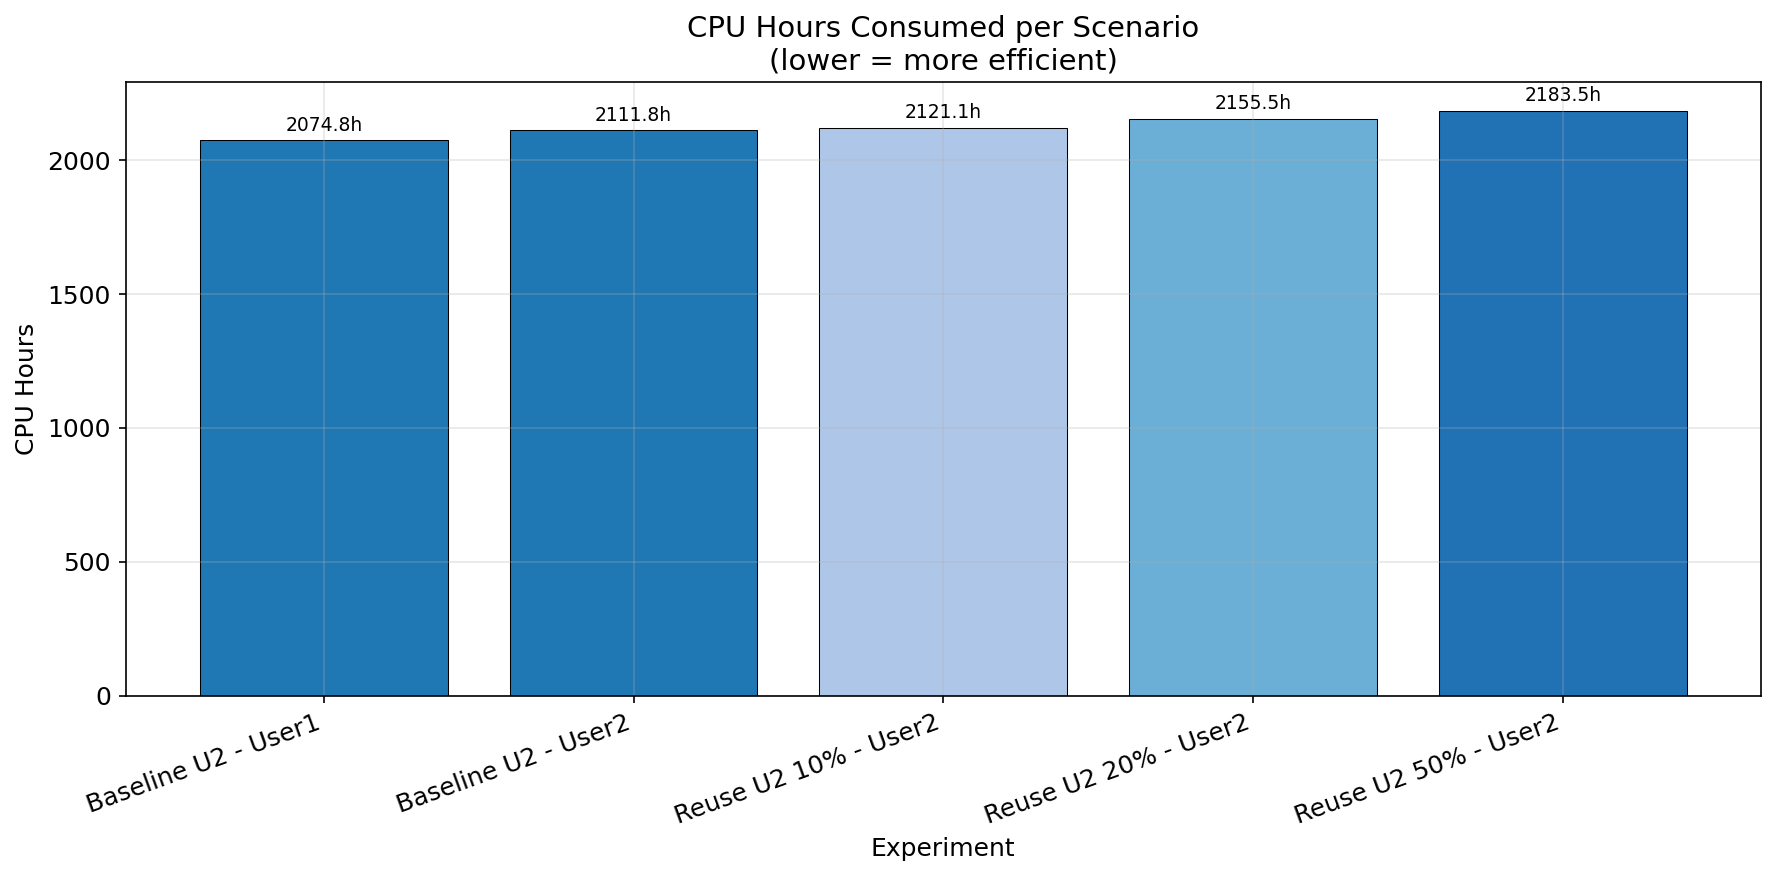

Saved: cpu_hours.pdf


In [9]:
def parse_memory(s):
    if pd.isna(s): return None
    s = str(s).strip()
    for val, unit in re.findall(r'([\d.]+)\s*(KB|MB|GB|TB|B)', s):
        val = float(val)
        if unit == 'B': return val
        elif unit == 'KB': return val * 1024
        elif unit == 'MB': return val * 1024**2
        elif unit == 'GB': return val * 1024**3
        elif unit == 'TB': return val * 1024**4
    return None

# CPU hours per scenario
cpu_hours = {}
for name, df in trace_data.items():
    df = df.copy()
    df['duration_s'] = df['realtime'].apply(parse_duration)
    df['cpu_pct'] = df['%cpu'].str.replace('%','').astype(float) / 100
    df['cpu_seconds'] = df['duration_s'] * df['cpu_pct']
    cpu_hours[name] = df['cpu_seconds'].sum() / 3600

fig, ax = plt.subplots(figsize=(12, 6))
names = list(cpu_hours.keys())
values = list(cpu_hours.values())
colors = ['#1f77b4', '#1f77b4', '#aec7e8', '#6baed6', '#2171b5']

bars = ax.bar(names, values, color=colors, edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2., v*1.01, f'{v:.1f}h', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Experiment')
ax.set_ylabel('CPU Hours')
ax.set_title('CPU Hours Consumed per Scenario\n(lower = more efficient)')
ax.set_xticklabels(names, rotation=20, ha='right')
plt.tight_layout()
plt.savefig('cpu_hours.pdf', bbox_inches='tight')
plt.show()
print('Saved: cpu_hours.pdf')

## Plot 8 — Nextflow: Peak Memory Usage per Scenario

/var/folders/vk/d03r7hzd5p9c3zdtvt3xrhc40000gn/T/ipykernel_12530/3201512307.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, rotation=20, ha='right')


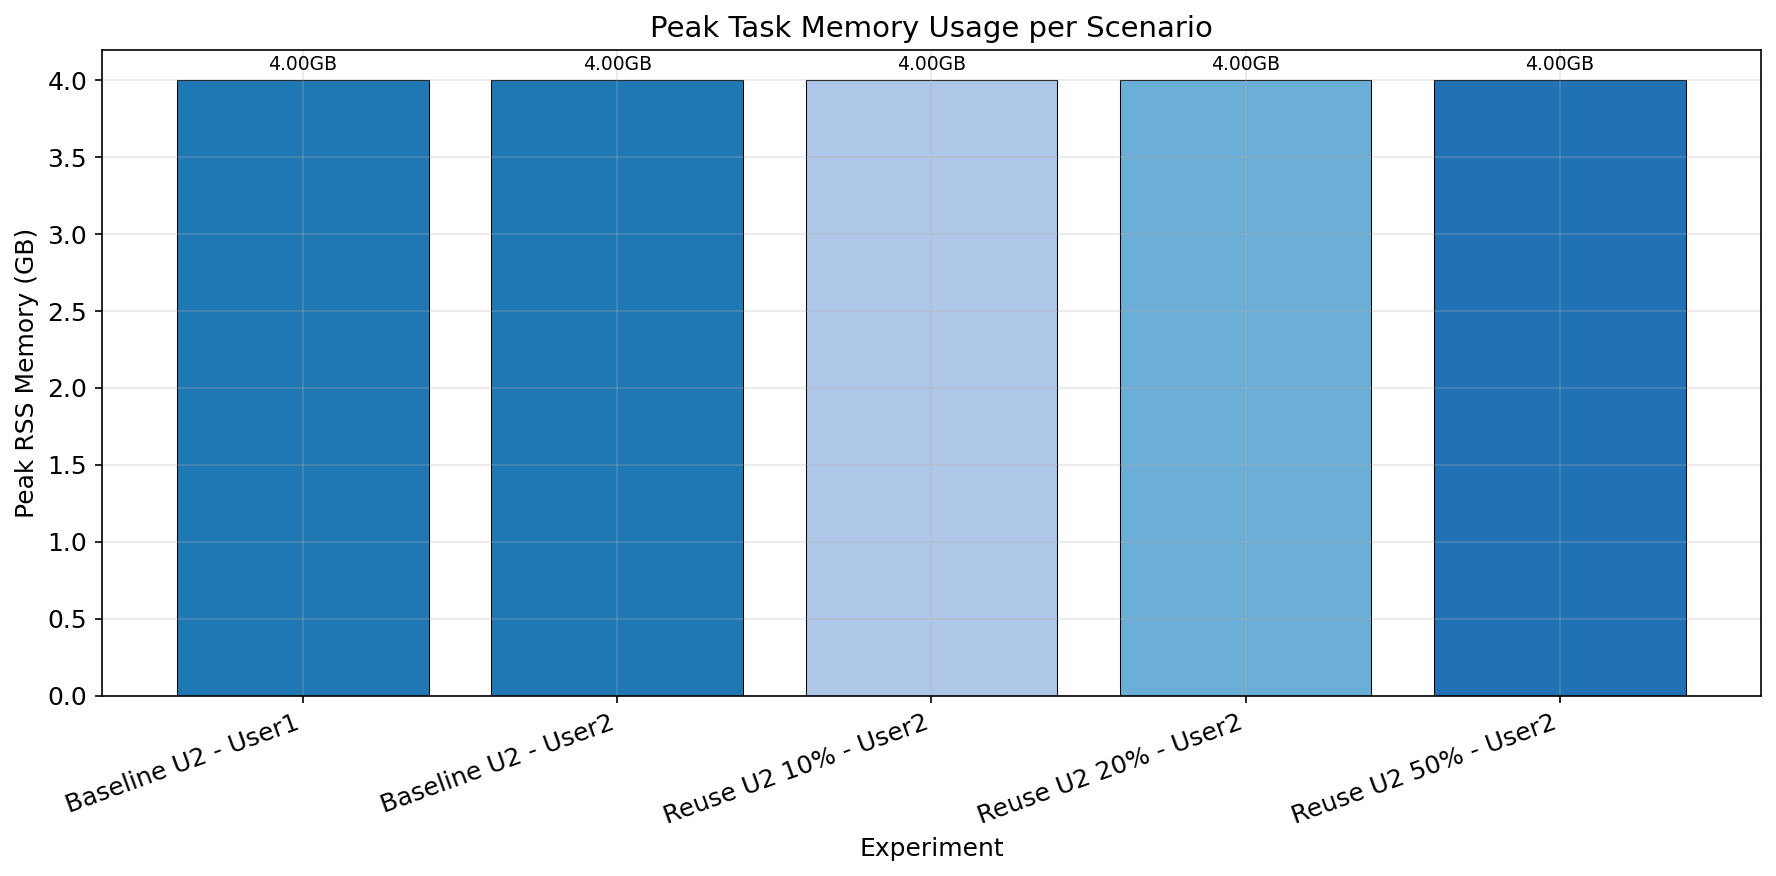

Saved: peak_memory.pdf


In [10]:
peak_mem = {}
for name, df in trace_data.items():
    df = df.copy()
    df['peak_rss_bytes'] = df['peak_rss'].apply(parse_memory)
    peak_mem[name] = df['peak_rss_bytes'].max() / (1024**3)  # GB

fig, ax = plt.subplots(figsize=(12, 6))
names = list(peak_mem.keys())
values = list(peak_mem.values())

bars = ax.bar(names, values, color=colors, edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, values):
    if v:
        ax.text(bar.get_x() + bar.get_width()/2., v*1.01, f'{v:.2f}GB', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Experiment')
ax.set_ylabel('Peak RSS Memory (GB)')
ax.set_title('Peak Task Memory Usage per Scenario')
ax.set_xticklabels(names, rotation=20, ha='right')
plt.tight_layout()
plt.savefig('peak_memory.pdf', bbox_inches='tight')
plt.show()
print('Saved: peak_memory.pdf')